<a href="https://colab.research.google.com/github/maxglaser-collab/tase-event-study/blob/main/Final_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Final Project**

##**1. Explanation of the program**

This program is designed to help users better understand and manage their personal
expenses. The user enters expense information manually, including the product name,
expense category, price, and currency. To keep the input consistent and reliable,
expense categories and supported currencies are loaded from a configuration text file
and used to validate the user’s input.

Once the data is collected, the program converts all expenses into EUR using a live
currency exchange API. The converted data is then analyzed and visualized through
multiple graphs that is showing spending patterns between products and categories. In
addition to the calculated results, a large language model (LLM) is used to generate
a short summary and a practical recommendation based on the user’s spending behavior.

Finally, the results of the analysis are displayed directly in the notebook and saved
to a text file, allowing the user to keep a permanent summary of their spending.
Overall, the program provides a simple but informative way to track expenses and gain
insights into personal spending habits.


##**2. Imports and libraries**

In [ ]:
# Used to work with files and check if files exist
import os

# Used to send requests to external APIs
import requests

# Used to create graphs and visualizations
import matplotlib.pyplot as plt

##**3. Loading the file in to the notebook**

In [ ]:
import os  # this is importing the os module to work with files and folders

# here it's checking if the file "data.txt" already exists in the current directory
if not os.path.exists("data.txt"):

    # If the file does NOT exist, it's being downloaded from my Google Drive
    # the part (-O data.txt) means: it's being saved the downloaded file with the name "data.txt"
    !wget -O data.txt "https://drive.google.com/uc?export=download&id=1f3_b34_XsRGVixbux_38u8ldlJ9m4GlF"

    # with this print function the user is being informend that the file was downloaded successfully
    print("Configuration file downloaded.")

else:
    # here it's running if the file already exists, it won't be downloaded again
    print("Configuration file already exists. Skipping download.")

# then it's being displayed all files that are currently working directory
# This helps verify that data.txt is available
os.listdir()



--2026-07-16 10:44:57--  https://drive.google.com/uc?export=download&id=1f3_b34_XsRGVixbux_38u8ldlJ9m4GlF
Resolving drive.google.com (drive.google.com)... 74.125.135.113, 74.125.135.139, 74.125.135.102, ...
Connecting to drive.google.com (drive.google.com)|74.125.135.113|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1f3_b34_XsRGVixbux_38u8ldlJ9m4GlF&export=download [following]
--2026-07-16 10:44:57--  https://drive.usercontent.google.com/download?id=1f3_b34_XsRGVixbux_38u8ldlJ9m4GlF&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 74.125.195.132, 2607:f8b0:400e:c09::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|74.125.195.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 182 [application/octet-stream]
Saving to: ‘data.txt’

data.txt            100%[===================>]     182  --.-KB/s    in 0s      



['.config', 'data.txt', 'sample_data']

##**4. Showing what is in the file that has been created**

In [ ]:
# here it's opening the file "data.txt" in read mode
# this function does the following: encoding="utf-8-sig" this ensures that  special characters are handled correctly
with open("data.txt", "r", encoding="utf-8-sig") as file:

    # this is shwoing the entire content of the file on to the screen
    print(file.read())


EXPENSE CATEGORIES
food
rent
transport
utilities
shopping
health
education
subscriptions
other


SUPPORTED CURRENCIES
EUR
USD
JPY
GBP
AUD
CAD
CHF
CNY
HKD
ILS


##**5. Loading the categories and currencies into Pyhton**

In [ ]:
# this is creating an empty list to store the expense categories
categories = []

# this is creating an empty list to store the supported currencies
currencies = []

# here the variable that is indicating whether we are reading categories or currencies
current_section = None # the value none will be updated once a section header is found

# this is opening the configuration file in read mode
with open("data.txt", "r", encoding="utf-8-sig") as file:

    # here there is a loop running through each line in the file
    for line in file:

        # this is removing leading/trailing spaces and newline characters
        line = line.strip()

        # if there is an empty line in the file it will be skipped
        if not line:
            continue

        # here it's being detected where the start of the expense categories is starting
        if line == "EXPENSE CATEGORIES":
            current_section = "categories"
            continue

        #here it's being detected where the start of the supported categories is starting
        if line == "SUPPORTED CURRENCIES":
            current_section = "currencies"
            continue

        # when the code is reading the categories section, and then it's storing the category
        # the categories are converted to lowercase for easier usage after but the input can be in uppercase or lower case
        if current_section == "categories":
            categories.append(line.lower())

        # when the code is reading the categories section, and then it's storing the currencies
        # currencies are converted to uppercase but the user is still allowed to put in uppercase/lowercase user
        elif current_section == "currencies":
            currencies.append(line.upper())

# this is being shown to the user

# here it's showing all available expense categories
print("Available expense categories:")
for category in categories:
    print("-", category)

# here it's showing all available supported currencies
print("\nSupported currencies:")
for currency in currencies:
    print("-", currency)



Available expense categories:
- food
- rent
- transport
- utilities
- shopping
- health
- education
- subscriptions
- other

Supported currencies:
- EUR
- USD
- JPY
- GBP
- AUD
- CAD
- CHF
- CNY
- HKD
- ILS


##**6. User Input and Expense Calculation**

In [ ]:
# here the variable keeps track of how many products the user has entered
product_count = 1 #the function product_count starts at 1 because it is used for human-readable numbering Product 1, Product 2....
# this empty list will store all expenses entered by the user
expenses = []

# these variables will store only the last expense
# they are used later in Chapter 7
last_price = None
last_currency = None

# this loop will keep running until the user says "no"
while True:

    # if this is not the first product, print a separator to visually separate entries
    if product_count > 1:
        print("\n" + "-" * 30 + "\n")

    # this is asking the user for the product name
    product = input("What product did you buy? ").strip()

    # this loop checks that the product name contains only letters and spaces
    while not product.replace(" ", "").isalpha():
        print("Invalid input. Please use words only.")
        product = input("What product did you buy? ").strip()

    # this is asking the user for the expense category
    category = input("In which category does it belong? ").strip().lower()

    # this loop checks that the category exists in the predefined categories list
    while category not in categories:
        print("Invalid category. Please choose from the available categories.")
        category = input("In which category does it belong? ").strip().lower()

    # this is asking the user for the price
    price = input("How much did it cost? ").strip()

    # this loop makes sure the price is a valid number allowing one decimal poiny
    while not price.replace(".", "", 1).isdigit():
        print("Invalid amount. Please enter a number.")
        price = input("How much did it cost? ").strip()

    # this is converting the price from a text input (string) to a number (float)
    price = float(price)

    # this is asking the user for the currency
    currency = input("Which currency did you buy it in? ").strip().upper()

    # this loop checks that the currency is being supported
    while currency not in currencies:
        print("Invalid currency. Please choose from the supported currencies.")
        currency = input("Which currency did you buy it in? ").strip().upper()

    # this is storing the last entered price and currency
    # these values will be used in Chapter 7
    last_price = price
    last_currency = currency

    # this is storing the current expense as a dictionary, this stores values using named keys instead of numeric indexes
    # and it's adding it to the expenses list
    expenses.append({
        "product": product,
        "category": category,
        "amount": price,
        "currency": currency
    })

    # this is printing all the inputs
    print()
    print(f"Product {product_count}:")
    print("Product name:", product)
    print("Expense category:", category)
    print("Price:", price, currency)
    print("Currency bought in:", currency)
    print("Value in EUR: calculated later")

    # this is increasing the product counter by 1
    product_count += 1

    # this is asking the user if they want to add another expense
    another = input("\nDo you have another expense? (yes/no) ").strip().lower()

    # this validates the yes/no answer
    while another not in ["yes", "no"]:
        print("Please answer yes or no.")
        another = input("Do you have another expense? (yes/no) ").strip().lower()

    # here if the user says no, exit the loop
    if another == "no":
        print("\nNo more expenses.")
        break


What product did you buy? apples
In which category does it belong? shopping
How much did it cost? 30
Which currency did you buy it in? pounds
Invalid currency. Please choose from the supported currencies.
Which currency did you buy it in? gpd
Invalid currency. Please choose from the supported currencies.
Which currency did you buy it in? gdp
Invalid currency. Please choose from the supported currencies.
Which currency did you buy it in? eur

Product 1:
Product name: apples
Expense category: shopping
Price: 30.0 EUR
Currency bought in: EUR
Value in EUR: calculated later

Do you have another expense? (yes/no) yes

------------------------------

What product did you buy? laptop
In which category does it belong? education
How much did it cost? 4000
Which currency did you buy it in? ils

Product 2:
Product name: laptop
Expense category: education
Price: 4000.0 ILS
Currency bought in: ILS
Value in EUR: calculated later

Do you have another expense? (yes/no) no

No more expenses.


##**7. Currency conversion (EUR)**

In [ ]:
#this is making the requests functions available so the program can send web requests
import requests


In [ ]:
#these are the supported currencies
SUPPORTED_CURRENCIES = [
    "EUR", "USD", "JPY", "GBP", "AUD",
    "CAD", "CHF", "CNY", "HKD", "ILS"
]


###Currency Exchange Rate Function

This function is responsible for retrieving current exchange rates from an external API.
It separates the API logic from the rest of the program, making the code easier to read,
maintain, and reuse when converting multiple expenses to EUR.


In [ ]:
# this is defining a function that retrieves exchange rates from an online API
def get_exchange_rates():
    ...


    # this is storing the API URL that provides the latest exchange rates from EUR
    url = "https://api.frankfurter.app/latest?from=EUR"

    # this is sending a GET request to the API and store the server's response
    response = requests.get(url)

    # this is checking if the request was not successful (status code other than 200)
    if response.status_code != 200:
        # this is printing an error message showing the HTTP error code
        print("HTTP error:", response.status_code)
        # this is stoping the function and return None to indicate failure
        return None

    # this is converting the API response from JSON format into a Python dictionary
    data = response.json()

    # this is checking if the expected "rates" key is missing from the response
    if "rates" not in data:
        # this is printing an error message for unexpected API responses
        print("Unexpected API response:")
        # this is printing the full response for debugging purposes
        print(data)
        # this stops the function and return None
        return None

    # this returns only the exchange rates dictionary from the API response
    return data["rates"]


In [ ]:
# this runs the function and save the returned exchange rates
rates = get_exchange_rates()

# this is showing the result
rates



{'AUD': 1.6335,
 'BRL': 5.7954,
 'CAD': 1.6053,
 'CHF': 0.9256,
 'CNY': 7.7268,
 'CZK': 24.233,
 'DKK': 7.4754,
 'GBP': 0.85093,
 'HKD': 8.9412,
 'HUF': 359.65,
 'IDR': 20612.12,
 'ILS': 3.4226,
 'INR': 109.794,
 'ISK': 143.4,
 'JPY': 185.22,
 'KRW': 1701.97,
 'MXN': 19.881,
 'MYR': 4.6514,
 'NOK': 11.096,
 'NZD': 1.9608,
 'PHP': 70.361,
 'PLN': 4.3258,
 'RON': 5.2418,
 'SEK': 11.0473,
 'SGD': 1.4739,
 'THB': 38.375,
 'TRY': 53.644,
 'USD': 1.1406,
 'ZAR': 18.686}

In [ ]:
# this is creating an empty dictionary to store only the supported exchange rates
filtered_rates = {}

# this is running a loop through each currency in the supported currencies list
for currency in SUPPORTED_CURRENCIES:

    # this is checking if the currency is EUR
    if currency == "EUR":
        # this is setting EUR to 1 because 1 EUR equals 1 EUR
        filtered_rates["EUR"] = 1

    else:
        # this is getting the exchange rate for the currency and store it in the dictionary
        filtered_rates[currency] = rates.get(currency)


In [ ]:
# this is displaying the dictionary containing the filtered exchange rates
filtered_rates



{'EUR': 1,
 'USD': 1.1406,
 'JPY': 185.22,
 'GBP': 0.85093,
 'AUD': 1.6335,
 'CAD': 1.6053,
 'CHF': 0.9256,
 'CNY': 7.7268,
 'HKD': 8.9412,
 'ILS': 3.4226}

In [ ]:
# this is initializing a variable to store the total expenses converted to EUR
total_eur = 0

# this is looping through each expense stored in the expenses list
for item in expenses:

    # this is extracting the product name from the expense dictionary
    product = item["product"]

    # this is extracting the amount spent from the expense dictionary
    amount = item["amount"]

    # this is extracting the currency used from the expense dictionary
    currency = item["currency"]

    # this is getting the exchange rate for the currency
    rate = filtered_rates.get(currency)

    # here if the exchange rate is missing, print an error and skip this expense
    if rate is None:
        print(f"Missing exchange rate for {currency}")
        continue

    # this is converting the expense amount to EUR
    eur_value = amount / rate

    # this is adding the converted value to the total EUR amount
    total_eur += eur_value

    # this is printing the converted EUR value for the current product
    print(
        f"The expense in EUR for buying {product} is: €{eur_value:.2f}"
    )

# here it's being printed the total expenses converted to EUR, rounded to two decimals
print("\nTotal expenses in EUR: €", round(total_eur, 2))



The expense in EUR for buying apples is: €30.00
The expense in EUR for buying laptop is: €1168.70

Total expenses in EUR: € 1198.7


##**8. Graphs**


In [ ]:
# import matplotlib's plotting module so the program can create charts and graphs
import matplotlib.pyplot as plt


In [ ]:
# this is creating an empty list to store product names
products = []

# this is creating an empty list to store expense amounts converted to EUR
amounts_eur = []

# this is creating an empty list to store expense categories
categories_list = []

# this is looping through each expense in the expenses list
for item in expenses:

    # this is extracting the product name from the expense dictionary
    product = item["product"]

    # this is extracting the original amount from the expense dictionary
    amount = item["amount"]

    # this is extracting the currency from the expense dictionary
    currency = item["currency"]

    # this is extracting the category from the expense dictionary
    category = item["category"]

    # this is getting the exchange rate for the currency
    rate = filtered_rates.get(currency)

    # here ,if the exchange rate is missing, the expense is being skipped
    if rate is None:
        continue

    # here the amount is converted the amount to EUR
    eur_value = amount / rate

    # here the product name is added to the products list
    products.append(product)

    # here the converted EUR amount is added to the amounts list
    amounts_eur.append(eur_value)

    # here the category is added to the categories list
    categories_list.append(category)



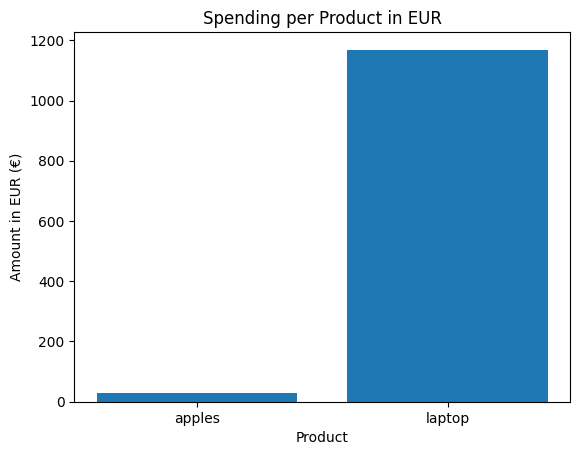

In [ ]:
# this is creating a new empty figure for the plot
plt.figure()

# this is creating a bar chart using product names and their EUR amounts
plt.bar(products, amounts_eur)

# this is labeling the x-axis with product names
plt.xlabel("Product")

# here the label the y-axis with amounts in EUR
plt.ylabel("Amount in EUR (€)")

# this is adding a title to the chart
plt.title("Spending per Product in EUR")

# this is displaying the chart on the screen
plt.show()


In [ ]:
# this is creating an empty dictionary to store total spending per category
category_totals = {}

# this is looping through categories and EUR amounts at the same time
for category, amount in zip(categories_list, amounts_eur):

    # this is checking if the category already exists in the dictionary
    if category in category_totals:
        # this is adding the amount to the existing category total
        category_totals[category] += amount

    else:
        # ths is creating a new category entry with the initial amount
        category_totals[category] = amount


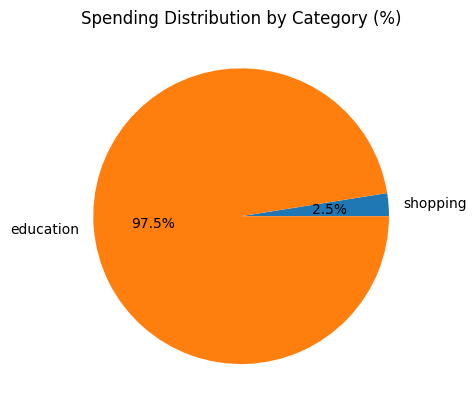

In [ ]:
# this is creating a new figure for the pie chart
plt.figure()

# this is creating a pie chart showing spending distribution by category
plt.pie(
    category_totals.values(),   # here the values are representing the total spending amounts
    labels=category_totals.keys(),  # here the labels represent category names
    autopct='%1.1f%%'           # percentages with one decimal place will be showing
)

# this is adding a title to the pie chart
plt.title("Spending Distribution by Category (%)")

# this is displying the pie chart
plt.show()



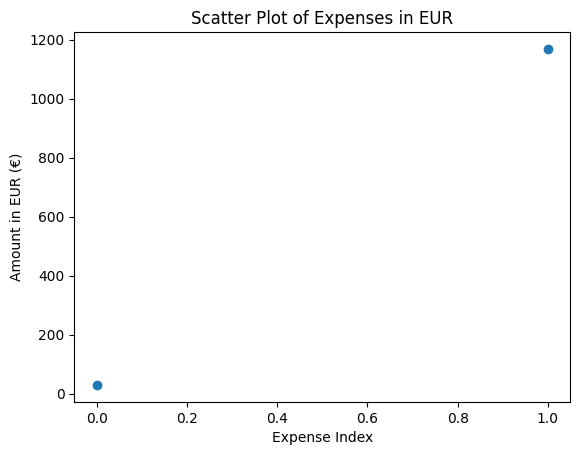

In [ ]:
# this is creating a new figure for the scatter plot
plt.figure()

# this is creating a scatter plot using expense index and EUR amounts
plt.scatter(range(len(amounts_eur)), amounts_eur)

# this labels the x-axis as the expense index
plt.xlabel("Expense Index")

# this labels the y-axis as the amount in EUR
plt.ylabel("Amount in EUR (€)")

# this adds a title to the scatter plot
plt.title("Scatter Plot of Expenses in EUR")

# this displays the scatter plot
plt.show()



##**9. Summary of spending**

In [ ]:
# this installs the groq library in to this notebook

!pip install -q groq


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 4.1 MB/s eta 0:00:00


In [ ]:
# this is importing the Groq class from the groq library to use the Groq API
from groq import Groq


In [ ]:
# this is importing the os module to work with files and file paths
import os

# this stores the Google Drive file ID that contains the Groq API key
GROQ_FILE_ID = "1-t8Dma0WN_0UHr9MLo650v9SPl8LrmuV"

# this checks if the API key file does not already exist
if not os.path.exists("groq_api_key.txt"):

    # this is downloading the API key file from Google Drive
    !wget -O groq_api_key.txt "https://drive.google.com/uc?export=download&id={GROQ_FILE_ID}"

    # this informs the user that the file was downloaded
    print("Groq API key file downloaded.")

else:
    # this informs the user that the file already exists
    print("Groq API key file already exists. Skipping download.")

# this opens the API key file in read mode
with open("groq_api_key.txt", "r", encoding="utf-8-sig") as file:

    # this reads the API key from the file and remove extra whitespace
    GROQ_API_KEY = file.read().strip()

# this checks that the API key is not empty or invalid
if not GROQ_API_KEY or GROQ_API_KEY.startswith("<"):

    # this stops the program if the API key is missing or incorrect
    raise ValueError("Groq API key file is empty or invalid.")

# this imports the Groq class from the groq library
from groq import Groq

# this creates a Groq client using the API key
client = Groq(api_key=GROQ_API_KEY)



--2026-07-16 10:46:09--  https://drive.google.com/uc?export=download&id=1-t8Dma0WN_0UHr9MLo650v9SPl8LrmuV
Resolving drive.google.com (drive.google.com)... 74.125.195.139, 74.125.195.101, 74.125.195.102, ...
Connecting to drive.google.com (drive.google.com)|74.125.195.139|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1-t8Dma0WN_0UHr9MLo650v9SPl8LrmuV&export=download [following]
--2026-07-16 10:46:09--  https://drive.usercontent.google.com/download?id=1-t8Dma0WN_0UHr9MLo650v9SPl8LrmuV&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 74.125.195.132, 2607:f8b0:400e:c09::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|74.125.195.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 59 [application/octet-stream]
Saving to: ‘groq_api_key.txt’

groq_api_key.txt    100%[===================>]      59  --.-KB/s    in 0s 

In [ ]:
# this creates a Groq client using the API key to authenticate API requests
client = Groq(api_key=GROQ_API_KEY)


In [ ]:
# this counts the total number of expenses recorded
total_expenses = len(expenses)

# this creates a set of unique categories used in the expenses
categories_used = set(item["category"] for item in expenses)

# this creates a formatted summary text using the collected data
summary_text = f"""
Number of expenses: {total_expenses}
Total spending in EUR: €{total_eur:.2f}
Categories used: {', '.join(categories_used)}
"""



In [ ]:
prompt = f"""
You are generating a formatted summary of an expense-tracking program.

Write a concise summary using Markdown.
Use ONLY the information provided below.
Do NOT invent data.
Do NOT repeat information.

Required structure:
- A short title
- A bullet list with:
  - how many expenses were reported
  - which categories were used
  - the total amount spent in EUR (this must be in bold)
- One short sentence summarizing the overall spending
- ONE short recommendation for the USER on how to manage their spending better
  (e.g. budgeting, reviewing large expenses)

Expense data:
{summary_text}
"""

#This code creates a multi-line prompt that tells the AI exactly how to generate a summary of the expense data.
#It restricts the AI to use only the calculated results from the program and defines a clear output structure using Markdown.
#By doing this, the program ensures the AI produces a consistent, concise, and controlled summary without inventing information.


In [ ]:
# this is sending the prompt to the AI model and request a completion
completion = client.chat.completions.create(
    model="llama-3.1-8b-instant",
    messages=[
        {"role": "user", "content": prompt}
    ]
)

# this extracts the generated text from the AI response
ai_summary = completion.choices[0].message.content

# this prints a title for the AI-generated summary
print("AI-Generated Spending Summary:\n")

# this displays the AI-generated summary
print(ai_summary)


AI-Generated Spending Summary:

**Expense Tracker Summary**
### Expense Data

* Total Expenses: 2
* Categories Used: shopping, education
* Total Amount Spent: **€1,198.70**

The majority of spending went towards shopping and education-related expenses.

To manage your spending more effectively, consider regularly reviewing your large expenses to identify areas for reduction or reallocation.


##**10.Summary saving to .txt file**

In [ ]:
# this creats a text file in write mode
with open("expense_summary.txt", "w", encoding="utf-8") as file:

    # this writes a title at the top of the file
    file.write("AI-Generated Expense Summary\n")

    # this writes a separator line for readability
    file.write("=" * 30 + "\n\n")

    # this writes the AI-generated summary content
    file.write(ai_summary)

# this informs the user that the summary was saved
print("\nSummary saved to expense_summary.txt")




Summary saved to expense_summary.txt
